# Filtro RC pasabajos en tiempo y frecuencia

## Pregunta de trabajo

¿Pueden dos descripciones matemáticas distintas, la convolución en el tiempo y el producto en frecuencia, predecir la misma respuesta de un circuito RC? ¿Y pueden explicar cuánto se atenúa y cuánto se retrasa cada frecuencia?

## Sistema

Circuito RC en serie, con el capacitor descargado al inicio. La entrada es el voltaje de la fuente y la salida es el voltaje del capacitor. Los valores son R = 1 kΩ y C = 1 µF, así que τ = RC = 1 ms. La ecuación del circuito es τ dy/dt + y = x(t).

## Entradas

1. Una senoidal encendida entre 0 y 60 ms, con tres frecuencias: ωτ = 0,2, 1 y 5.
2. La suma de dos senoidales, una con ωτ = 0,2 y otra con ωτ = 5, también encendida entre 0 y 60 ms.

Los estudios numéricos de truncamiento y de paso usan una sola senoidal con ωτ = 1 encendida entre 0 y 20 ms. La comparación lineal contra circular usa una con ωτ = 1 encendida hasta el final del registro (30 ms). El estudio numérico principal es el truncamiento de h; el paso Δt y el relleno de la FFT se revisan como complemento.

## Qué se calcula y con qué se compara

La salida se calcula de tres maneras:

- convolución directa, y[n] = Δt Σ h[k] x[n−k];
- convolución por FFT, rellenando con ceros hasta N + M − 1 muestras;
- solución analítica de la ecuación del circuito, que sirve de referencia independiente.

Después se compara la salida de las tres rutas y se mide la amplitud y la fase en la zona donde el transitorio ya terminó y la fuente todavía está encendida. Esos valores se contrastan con |H(ω)| y arg H(ω), donde H(ω) = 1/(1 + iωτ).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image
from src.sistema import respuesta_impulsional, H_analitica
from src.entradas import sinusoide_encendida, suma_sinusoides_encendida
from src.convolucion import conv_directa, conv_fft
from src.validacion import salida_analitica, estimar_componentes
from src.resultados import (tabla_metodos, tabla_amplitud_fase,
                            tabla_truncamiento, tabla_paso,
                            tabla_lineal_vs_circular, error_superposicion,
                            tabla_compuesta, tabla_H_truncada)
from src.graficas import figura_H, figura_compuesta, figura_transitorio

plt.rcParams["figure.dpi"] = 80

## Modelo

**Ecuación del circuito.** La ley de voltajes de Kirchhoff da x(t) = V_R + y(t), con y(t) el
voltaje del capacitor. La resistencia cumple V_R = R i, y el capacitor cumple i = C dy/dt.
Al juntar las tres relaciones queda

$$\tau \frac{dy}{dt} + y = x(t), \qquad \tau = RC.$$

La ecuación es lineal y tiene coeficientes constantes (R y C no cambian en el tiempo). Por
eso el sistema es lineal e invariante en el tiempo, y se puede describir con una
convolución: $y(t) = (h * x)(t)$.

**Función de transferencia.** Con $X(\omega)=\int x(t)e^{-i\omega t}dt$, derivar en el tiempo
equivale a multiplicar por $i\omega$. La ecuación queda $(1+i\omega\tau)Y = X$, y entonces

$$H(\omega) = \frac{1}{1+i\omega\tau}.$$

**Respuesta impulsional.** Hay dos caminos y dan lo mismo.

1. Por el impulso: se integra $\tau y' + y = \delta(t)$ cerca de $t=0$. Como el capacitor
   parte descargado, $y(0^+) = 1/\tau$, y para $t>0$ la ecuación es $\tau h' + h = 0$.
2. Por residuos: $h(t)=\frac{1}{2\pi}\int H(\omega)e^{i\omega t}d\omega$. El integrando tiene un
   polo simple en $\omega = i/\tau$, en el semiplano superior. Para $t>0$ se cierra el
   contorno por arriba y el residuo da $e^{-t/\tau}/(i\tau)$. Para $t<0$ se cierra por abajo,
   donde no hay polos, y la integral vale cero.

En los dos casos

$$h(t) = \frac{1}{\tau}\,e^{-t/\tau}\,u(t).$$

Que $h(t)=0$ para $t<0$ es la causalidad: el capacitor no responde antes de que llegue el
estímulo. Además $\int h\,dt = 1$, que equivale a $H(0)=1$ (una señal constante pasa sin cambio).

**Módulo y fase.**

$$|H(\omega)| = \frac{1}{\sqrt{1+(\omega\tau)^2}}, \qquad \arg H(\omega) = -\arctan(\omega\tau).$$

En $\omega = 1/\tau$ el módulo vale $1/\sqrt{2}\approx 0{,}707$ (−3 dB) y la fase es −45°.

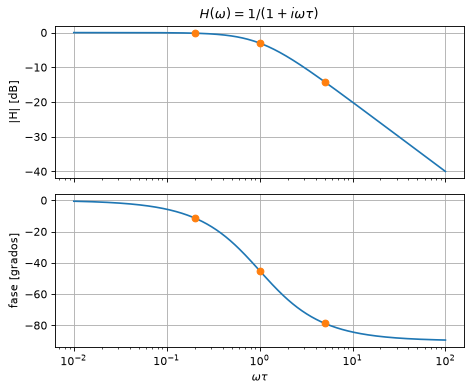

In [2]:
fig = figura_H()

### Qué muestra H(ω)

El módulo es casi 1 para ωτ pequeño, vale 0,707 (−3 dB) en ωτ = 1 y cae unos 20 dB por década después. La fase baja de 0° a −90° y pasa por −45° en el corte. Los puntos marcados son las frecuencias del proyecto. La frecuencia f y la frecuencia angular ω se relacionan con ω = 2πf, y en todo el notebook se trabaja con ω.

| ωτ | ω [rad/s] | f [Hz] | módulo | fase |
|---|---|---|---|---|
| 0,2 | 200 | 31,8 | 0,981 | −11,3° |
| 1 | 1000 | 159 | 0,707 | −45,0° |
| 5 | 5000 | 796 | 0,196 | −78,7° |

## Método

**Convolución directa.** Se aproxima la integral $y(t)=\int h(\tau)\,x(t-\tau)\,d\tau$ con una suma de rectángulos de ancho $\Delta t$:

$$y[n] = \Delta t \sum_k h[k]\,x[n-k].$$

La función recorre los valores de $h$, y cada $h[k]$ multiplica a toda la señal $x$ desplazada $k$ posiciones. No usa `np.convolve`. El factor $\Delta t$ es necesario porque $h$ tiene unidades de 1/s: sin él, la salida quedaría $1/\Delta t$ veces más grande (100 veces con $\Delta t=\tau/100$). Si $x$ tiene $N$ muestras y $h$ tiene $M$, la salida tiene $N+M-1$.

**Convolución por FFT.** Se calcula la FFT de $x$ y de $h$, se multiplican y se invierte:

$$y = \Delta t\;\mathcal{F}^{-1}\{X\cdot H\}.$$

La FFT de NumPy no lleva factor de normalización en la ida y la inversa divide por la longitud, así que sale justo la suma de productos. El $\Delta t$ se agrega por la misma razón que antes.

**Relleno con ceros.** El producto de FFT corresponde a una convolución circular. Para que coincida con la lineal, las dos señales se rellenan con ceros hasta $L \ge N+M-1$. Con una longitud menor, la cola de la salida da la vuelta y se suma al inicio. En una prueba con FFT de longitud $N$ y una senoidal que sigue encendida hasta el final del registro, el error relativo subió de $10^{-15}$ a $0{,}15$.

**Muestreo de h.** $h(t)$ salta de 0 a $1/\tau$ en $t=0$. Tomar $h[0]=1/\tau$ completo sobreestima el primer rectángulo, así que se usa la mitad (regla del trapecio). $h$ se corta en $10\tau$, donde queda $e^{-10}\approx 5\times10^{-5}$ de su área.

**Amplitud y fase.** En el tramo de 10 ms a 55 ms (después del transitorio y antes de apagar la fuente) se ajusta la salida a $a\sin(\omega t)+b\cos(\omega t)$ por mínimos cuadrados. La amplitud es $\sqrt{a^2+b^2}$ y la fase es $\operatorname{atan2}(b,a)$.

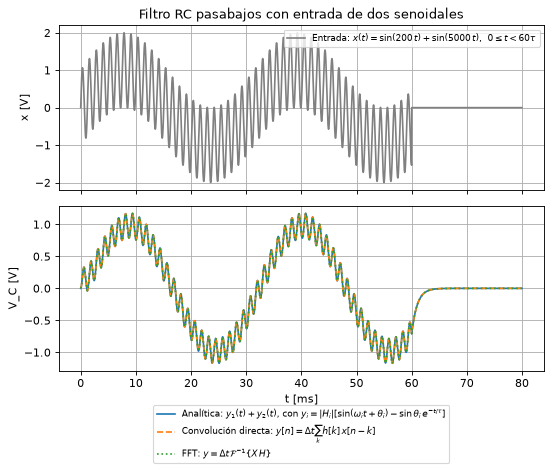

In [3]:
fig = figura_compuesta(guardar="figura_compuesta.png")

In [4]:
tabla_metodos()

,omega*tau,error rel. directa vs FFT,error max directa vs analitica,error max FFT vs analitica
0,0.2,1.471705e-15,0.002696,0.002696
1,1.0,1.639521e-15,0.001541,0.001541
2,5.0,1.715381e-15,0.004994,0.004994


### Directa, FFT y solución analítica

Las dos convoluciones dan la misma salida: el error relativo es de 1,5e-15 a 1,7e-15, o sea redondeo. Contra la solución analítica el error máximo es 0,0027, 0,0015 y 0,0050 V. Ese máximo cae en el instante en que se apaga la fuente, porque la entrada salta y la malla la muestrea mal en ese punto. Su tamaño coincide con |x(t_on)|/2 · Δt/τ, que depende de la fase de la senoidal justo cuando se corta, y por eso cambia con la frecuencia.

In [5]:
tabla_amplitud_fase()

,omega*tau,|H| teorico,amplitud medida,fase teorica [gr],fase medida [gr],error amplitud,error fase [gr]
0,0.2,0.980581,0.980601,-11.309932,-11.307513,0.000021,0.002419
1,1.0,0.707107,0.707134,-45.000000,-45.001174,0.000027,0.001174
2,5.0,0.196116,0.196098,-78.690068,-78.689589,0.000018,0.000478


### Amplitud y fase en régimen estacionario

Las amplitudes medidas (0,9806, 0,7071 y 0,1961) coinciden con |H(ω)| con errores menores a 3e-5, y las fases (−11,31°, −45,00° y −78,69°) con errores menores a 0,003°. El filtro deja pasar casi intacta la frecuencia baja y atenúa la alta a un 19,6 %. El desfase crece con la frecuencia y tiende a −90°.

In [6]:
tabla_truncamiento()

,k,area perdida,error max,exp(-k)
0,1,0.368798,0.278890,0.367879
1,2,0.135672,0.102600,0.135335
2,3,0.049910,0.037744,0.049787
3,5,0.006753,0.005105,0.006738
4,8,0.000334,0.000257,0.000335
5,10,0.000043,0.000033,0.000045


### Truncamiento de h

El área que se pierde al cortar h en kτ sigue a e^(−k), y el error en la salida cae al mismo ritmo: un factor de 2,7 por cada τ más que se conserve. Con k = 8 el error es 2,6e-4 y con k = 10 baja a 3,3e-5, donde ya se acerca al error de discretización.

In [7]:
tabla_lineal_vs_circular()

,L,muestras que dan la vuelta,error relativo,diferencia max
0,3000,799,1.481182e-01,5.663745e-01
1,3400,399,2.752587e-03,1.039115e-02
2,3799,0,1.265848e-15,3.663736e-15


### Convolución lineal y circular

El producto de FFT calcula una convolución circular de longitud L. La convolución lineal
tiene N + M − 1 = 3799 muestras, así que si L es menor, las muestras que sobran no
desaparecen: se enrollan y se suman al inicio.

Con L = N = 3000 se enrollan 799 muestras y el error relativo es 0,15. La diferencia máxima
(0,57 V) es el valor de la salida justo cuando termina el registro, porque la senoidal sigue
encendida y la cola arranca desde ahí. Con L = 3400 solo se enrollan las 399 muestras del
final de la cola, que ya decayó (e^−4 ≈ 0,018), y el error baja a 2,8e-3. Con
L = N + M − 1 no hay vuelta y coincide con la lineal hasta el redondeo (1e-15).

In [8]:
print("error de superposicion:", error_superposicion())
tabla_compuesta()

error de superposicion: 1.1102230246251565e-15


,omega*tau,|H| teorico,amplitud medida,fase teorica [gr],fase medida [gr],error amplitud,error fase [gr]
0,0.2,0.980581,0.980601,-11.309932,-11.307513,0.000021,0.002419
1,5.0,0.196116,0.196098,-78.690068,-78.689589,0.000018,0.000478


### Superposición y señal compuesta

La salida de la suma de las dos senoidales es la suma de las salidas de cada una (diferencia
de 1e-15). Es una propiedad de la convolución, que es lineal, así que esta prueba revisa
el código y no el circuito.

Lo que valida el circuito es la tabla: en la salida compuesta la componente lenta
(ωτ = 0,2) tiene amplitud 0,9806 y fase −11,31°, y la rápida (ωτ = 5) tiene 0,1961 y
−78,69°. Son |H| y arg H en cada frecuencia, con errores de 2e-5 en amplitud y menores a
0,003° en fase.

In [9]:
tabla_H_truncada()

,k,|H_num - H_k|,|H_num - H|,exp(-k)
0,3,0.000277,0.049907,0.049787
1,5,0.000212,0.006752,0.006738
2,10,0.000209,0.000210,0.000045


In [10]:
tabla_H_truncada(pasos=400)

,k,|H_num - H_k|,|H_num - H|,exp(-k)
0,3,0.000100,0.049846,0.049787
1,5,0.000057,0.006746,0.006738
2,10,0.000052,0.000052,0.000045


### H analítica y transformada de h truncada

La transformada de h cortada en kτ no es H(ω). Para ese núcleo hay una expresión exacta,
H_k(ω) = (1 − e^(−k) e^(−iωkτ)) / (1 + iωτ), que permite separar dos errores.

|H_num − H_k| mide solo la discretización de la transformada (≈ 2e-4 para los tres k).
|H_num − H| incluye además el corte de h: para k = 3 y 5 sigue a e^(−k), porque en ω = 0 la
diferencia es justo el área perdida. Con k = 10 el corte (4,5e-5) es menor que el error de
discretización, y las dos columnas dan casi lo mismo.

Al reducir el paso a la mitad (τ/400), |H_num − H_k| baja a casi la cuarta parte para k = 5 y
k = 10 (de 2,1e-4 a 5e-5), como corresponde a un error de segundo orden en Δt. Con k = 10 la
diferencia con H queda en 5e-5, cerca del límite del corte (e^−10 ≈ 4,5e-5).

In [11]:
tabla_paso()

,tau/dt,error h[0] completo,error h[0]/2
0,25,0.020332,0.000447
1,50,0.010234,0.000303
2,100,0.005210,0.000267
3,200,0.002705,0.000257
4,400,0.001457,0.000255


### Efecto del paso Δt

Con h[0] completo el error es de primer orden en Δt: se reduce a la mitad cada vez que se duplican los pasos (de 0,0203 con τ/Δt = 25 a 0,0015 con 400). Con h[0]/2 el error es mucho menor, pero se detiene en un piso de unos 2,5e-4. Ese piso coincide con el error de cortar h en 8τ (tabla de truncamiento, k = 8), que es el corte que usa esta tabla.

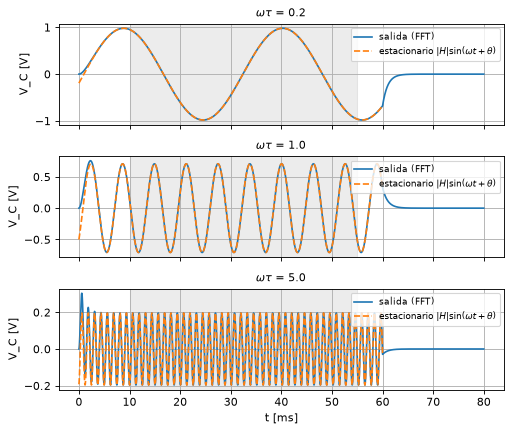

In [12]:
fig = figura_transitorio()

### Transitorio y régimen estacionario

Al encender la fuente, el capacitor está descargado y la salida no arranca en su valor
estacionario. La solución tiene dos partes: una senoidal de amplitud |H(ω)| y fase arg H(ω),
y un término transitorio que decae como e^(−t/τ). Después de unos 5τ (5 ms) el transitorio
ya es menor al 1 % y queda solo el régimen estacionario.

Por eso la amplitud y la fase se miden entre 10 ms y 55 ms (la franja gris), cuando el
transitorio ya terminó y la fuente todavía está encendida. En esa franja la salida coincide
con la curva punteada. Después de 60 ms, sin fuente, el capacitor se descarga con la misma
constante de tiempo.

Se ve también el efecto de la frecuencia: con ωτ = 0,2 la salida casi iguala a la entrada
y va poco retrasada; con ωτ = 5 la amplitud baja a 0,196 y el retraso es de casi 79°.

## Conclusiones

- La convolución directa y la FFT (con relleno hasta N + M − 1) dan la misma salida: el error
  relativo entre ellas es del orden de 1e-15, o sea redondeo.
- La salida calculada coincide con la solución analítica del circuito. El error máximo es de
  1e-3 a 5e-3 V y cae en el instante en que se apaga la fuente, por el salto de la entrada
  en la malla.
- La amplitud y la fase medidas en régimen estacionario coinciden con |H(ω)| y arg H(ω):
  errores de 2e-5 en amplitud y menores a 0,003° en fase.
- El filtro deja pasar la componente lenta (ωτ = 0,2, amplitud 0,98) y atenúa la rápida
  (ωτ = 5, amplitud 0,196), y la retrasa más (−78,7° contra −11,3°).
- Hay tres fuentes de error numérico: el salto de h en t = 0 (se corrige con h[0]/2), el salto de
  la entrada en el apagado, y el corte de h, que cae como e^−k.
- Sin relleno suficiente, la FFT calcula una convolución circular y la cola de la salida se enrolla al inicio. Con L = N + M − 1 coincide con la lineal. Con L = N el error relativo fue 0,15 y con L = N + M − 1 fue de 1e-15.

### Limitaciones

- Se estudió un solo circuito (τ = 1 ms) y entradas senoidales.
- El piso de error con h[0]/2 (unos 2,5e-4) coincide con el error de cortar h en 8τ (tabla de truncamiento, k = 8). Al cortar en 10τ baja a 3e-5.